# Detecção de Fraude em Transações de Cartão de Crédito

Projeto do bootcamp **Accenture – Python para Análise e Automação de Dados** (DIO).

**Objetivo:** treinar e comparar modelos que detectam fraude numa base extremamente desbalanceada, escolhendo as métricas certas (recall, precisão e F1 da classe de fraude), ajustando o limiar de decisão e explicando o modelo com SHAP.

**Roteiro:** 1) Explorar · 2) Preparar · 3) Treinar · 4) Avaliar · 5) Ajustar · 6) Explicar

In [18]:
# SHAP não vem instalado no Colab (XGBoost e scikit-learn já vêm)
!pip install -q shap

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, recall_score, precision_score, f1_score,
    roc_auc_score, average_precision_score,
    classification_report, confusion_matrix,
    RocCurveDisplay, PrecisionRecallDisplay,
)
from xgboost import XGBClassifier
import shap

RANDOM_STATE = 42
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## 1. Explorar

Colunas: `Time` (momento), `Amount` (valor), `Class` (1 = fraude, 0 = normal) e `V1`–`V28` (transformadas por PCA para proteger a privacidade).

In [20]:
URL = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
df = pd.read_csv(URL)   # lido direto do link: o arquivo não vai para o repositório

print("Formato:", df.shape)
print("Valores nulos:", int(df.isna().sum().sum()))
display(df.head())

Formato: (284807, 31)
Valores nulos: 0


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,...,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,...,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,...,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,...,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,...,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


In [21]:
contagem = df["Class"].value_counts()
proporcao = df["Class"].value_counts(normalize=True)
display(pd.DataFrame({"transacoes": contagem, "proporcao": proporcao}))

print(f"Fraudes: {contagem[1]} de {len(df)} ({proporcao[1]:.4%})")

,transacoes,proporcao
Class,,
0,284315,0.9983
1,492,0.0017


Fraudes: 492 de 284807 (0.1727%)


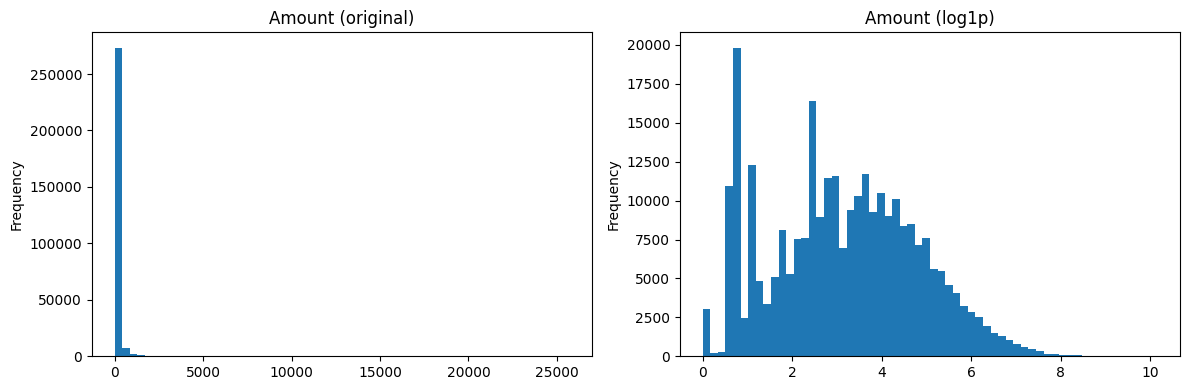

In [22]:
# Valor das transações: muito assimétrico, por isso vamos aplicar log depois
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df["Amount"].plot.hist(bins=60, ax=ax[0], title="Amount (original)")
np.log1p(df["Amount"]).plot.hist(bins=60, ax=ax[1], title="Amount (log1p)")
plt.tight_layout(); plt.show()

**Leitura:** A base tem 284.807 transações e apenas 492 são fraudes (0,1727%). Ou seja, 99,83% das transações são normais. Por isso, um modelo que responde "não é fraude" para tudo acertaria cerca de 99,8% das vezes e não detectaria nenhuma fraude. A acurácia, nesse caso, mede quase só a classe normal e engana. O que importa é o desempenho na classe rara, então vou avaliar os modelos por recall (fraudes reais encontradas), precisão (alarmes que eram fraude de fato) e F1. Também observei que `Amount` é muito assimétrico (a maioria dos valores é pequena, com poucos valores muito altos), e a transformação `log1p` deixa a distribuição bem mais equilibrada.


## 2. Preparar

- `np.log1p` em `Amount` para reduzir a assimetria.
- Divisão treino/teste com `stratify=y`, para manter a proporção de fraudes nos dois conjuntos.
- `StandardScaler` dentro do `Pipeline`: ele aprende média e desvio **só no treino**, evitando vazamento de dados do teste.

In [23]:
df_model = df.copy()
df_model["Amount"] = np.log1p(df_model["Amount"])

X = df_model.drop(columns="Class")
y = df_model["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print(f"Treino: {X_train.shape} | fraude = {y_train.mean():.4%}")
print(f"Teste : {X_test.shape} | fraude = {y_test.mean():.4%}")

Treino: (227845, 30) | fraude = 0.1729%
Teste : (56962, 30) | fraude = 0.1720%


## 3. Treinar

Quatro modelos, do mais simples ao mais forte:
1. Regressão logística **sem** tratar o desbalanceamento (baseline);
2. Regressão logística com `class_weight="balanced"`;
3. Random Forest com `class_weight="balanced"`;
4. XGBoost com `scale_pos_weight` (razão entre normais e fraudes).

In [24]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
peso_fraude = neg / pos
print(f"scale_pos_weight = {peso_fraude:.1f}")

def com_scaler(clf):
    return Pipeline([("scaler", StandardScaler()), ("clf", clf)])

modelos = {
    "Reg. Logística (baseline)": com_scaler(
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    "Reg. Logística (balanced)": com_scaler(
        LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)),
    # max_depth limitado para o treino não ficar lento no Colab (decisão a documentar no README)
    "Random Forest (balanced)": com_scaler(
        RandomForestClassifier(n_estimators=100, max_depth=12, class_weight="balanced",
                               n_jobs=-1, random_state=RANDOM_STATE)),
    "XGBoost": com_scaler(
        XGBClassifier(n_estimators=200, max_depth=4, scale_pos_weight=peso_fraude,
                      eval_metric="logloss", n_jobs=-1, random_state=RANDOM_STATE)),
}

probas = {}
for nome, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    probas[nome] = modelo.predict_proba(X_test)[:, 1]
    print("treinado:", nome)

scale_pos_weight = 577.3
treinado: Reg. Logística (baseline)
treinado: Reg. Logística (balanced)
treinado: Random Forest (balanced)
treinado: XGBoost


## 4. Avaliar

Mesmo limiar (0,5) para todos. Repare na coluna **acurácia** ao lado das métricas da classe de fraude.

In [25]:
def metricas(y_true, proba, limiar=0.5):
    pred = (proba >= limiar).astype(int)
    return {
        "acuracia": accuracy_score(y_true, pred),
        "recall": recall_score(y_true, pred),
        "precisao": precision_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred),
        "roc_auc": roc_auc_score(y_true, proba),
        "pr_auc": average_precision_score(y_true, proba),
    }

tabela = pd.DataFrame({nome: metricas(y_test, p) for nome, p in probas.items()}).T
tabela.index.name = "modelo"
tabela

,acuracia,recall,precisao,f1,roc_auc,pr_auc
modelo,,,,,,
Reg. Logística (baseline),0.9992,0.6531,0.8312,0.7314,0.9595,0.7386
Reg. Logística (balanced),0.9752,0.9184,0.0603,0.1131,0.9711,0.7113
Random Forest (balanced),0.9994,0.8061,0.8404,0.8229,0.9732,0.8314
XGBoost,0.9995,0.8265,0.8804,0.8526,0.9758,0.8805


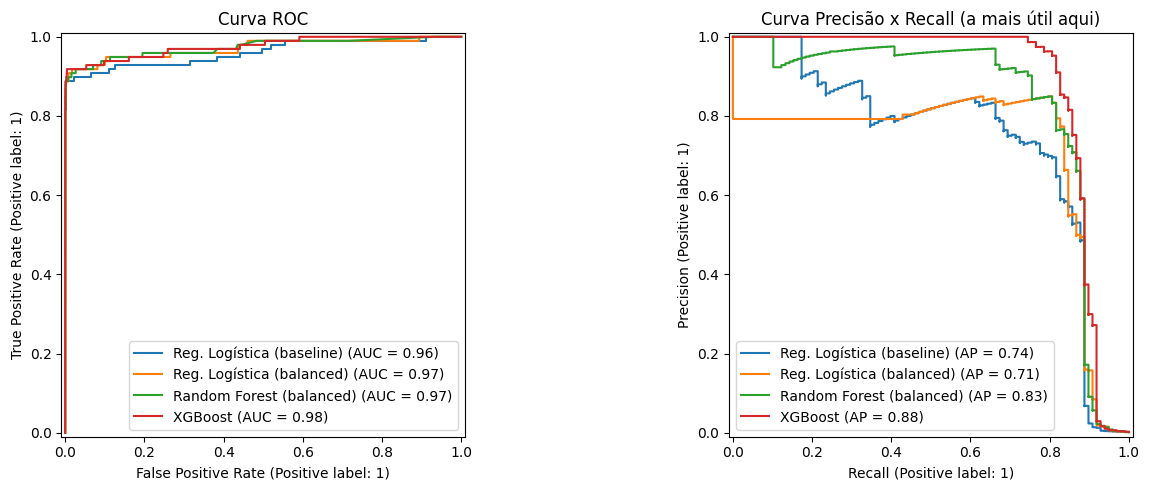

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for nome, proba in probas.items():
    RocCurveDisplay.from_predictions(y_test, proba, name=nome, ax=ax[0])
    PrecisionRecallDisplay.from_predictions(y_test, proba, name=nome, ax=ax[1])
ax[0].set_title("Curva ROC")
ax[1].set_title("Curva Precisão x Recall (a mais útil aqui)")
plt.tight_layout(); plt.show()

In [27]:
MELHOR = "XGBoost"   # TODO: troque pelo modelo que você escolher e justifique no README

pred = (probas[MELHOR] >= 0.5).astype(int)
print(f"Relatório de classificação: {MELHOR} (limiar 0,5)\n")
print(classification_report(y_test, pred, target_names=["normal", "fraude"], digits=4))
display(pd.DataFrame(confusion_matrix(y_test, pred),
                     index=["real: normal", "real: fraude"],
                     columns=["previsto: normal", "previsto: fraude"]))

Relatório de classificação: XGBoost (limiar 0,5)

              precision    recall  f1-score   support

      normal     0.9997    0.9998    0.9998     56864
      fraude     0.8804    0.8265    0.8526        98

    accuracy                         0.9995     56962
   macro avg     0.9401    0.9132    0.9262     56962
weighted avg     0.9995    0.9995    0.9995     56962



,previsto: normal,previsto: fraude
real: normal,56853,11
real: fraude,17,81


**Leitura:** O XGBoost foi o modelo mais equilibrado: pegou 81 das 98 fraudes do teste (recall de 0,8265) com precisão de 0,8804, ou seja, só 11 falsos alarmes, e teve a maior PR-AUC (0,88). A regressão logística com `class_weight="balanced"` teve o maior recall (0,9184), mas pagou um preço alto: precisão de 0,0603, o que significa que só cerca de 6% dos alertas eram fraude de verdade, algo inviável na prática. O Random Forest ficou no meio-termo (recall de 0,8061 e precisão de 0,8404), com apenas 2 fraudes a menos que o XGBoost, então a diferença de recall entre os dois é pequena num teste com só 98 fraudes. A acurácia não ajudou a diferenciar os modelos: todos ficaram acima de 0,97, e o baseline chegou a 0,9992 com recall de apenas 0,6531. Por isso, a escolha foi guiada por recall, precisão, F1 e pela curva Precisão x Recall, que separa bem os modelos, ao contrário da curva ROC.

## 5. Ajustar

Dois ajustes: o **limiar de decisão** (de 0,5 para valores menores, para pegar mais fraudes) e a busca de **hiperparâmetros** com `GridSearchCV` escolhendo pelo **recall**.

In [28]:
linhas = []
for limiar in [0.5, 0.4, 0.3, 0.2, 0.1]:
    m = metricas(y_test, probas[MELHOR], limiar)
    linhas.append({"limiar": limiar, "recall": m["recall"], "precisao": m["precisao"], "f1": m["f1"]})
pd.DataFrame(linhas).set_index("limiar")

,recall,precisao,f1
limiar,,,
0.5000,0.8265,0.8804,0.8526
0.4000,0.8265,0.8710,0.8482
0.3000,0.8367,0.8542,0.8454
0.2000,0.8469,0.8469,0.8469
0.1000,0.8571,0.7925,0.8235


In [29]:
# GridSearchCV com o Pipeline completo (scaler + modelo), escolhendo pelo recall
pipe = com_scaler(XGBClassifier(scale_pos_weight=peso_fraude, eval_metric="logloss",
                                n_jobs=-1, random_state=RANDOM_STATE))

param_grid = {
    "clf__max_depth": [3, 5],
    "clf__n_estimators": [100, 300],
    "clf__learning_rate": [0.05, 0.1],
}

grid = GridSearchCV(pipe, param_grid, scoring="recall", cv=3, n_jobs=1, verbose=1)
grid.fit(X_train, y_train)

print("Melhores parâmetros:", grid.best_params_)
print(f"Melhor recall (validação cruzada): {grid.best_score_:.4f}")

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Melhores parâmetros: {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 100}
Melhor recall (validação cruzada): 0.8782


In [30]:
# Correção: busca de hiperparâmetros pela PR-AUC (olha recall E precisão) e limiar escolhido pelo melhor F1
grid_ap = GridSearchCV(pipe, param_grid, scoring="average_precision", cv=3, n_jobs=1, verbose=1)
grid_ap.fit(X_train, y_train)
print("Melhores parâmetros:", grid_ap.best_params_)
print(f"Melhor PR-AUC (validação cruzada): {grid_ap.best_score_:.4f}\n")

modelo_final = grid_ap.best_estimator_
proba_final = modelo_final.predict_proba(X_test)[:, 1]

linhas = []
for limiar in [0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2, 0.1]:
    m = metricas(y_test, proba_final, limiar)
    linhas.append({"limiar": limiar, "recall": m["recall"], "precisao": m["precisao"], "f1": m["f1"]})
tab = pd.DataFrame(linhas).set_index("limiar")
display(tab)

LIMIAR = tab["f1"].idxmax()
pred_final = (proba_final >= LIMIAR).astype(int)

print(f"\nModelo final | limiar = {LIMIAR}\n")
print(classification_report(y_test, pred_final, target_names=["normal", "fraude"], digits=4))
display(pd.DataFrame(confusion_matrix(y_test, pred_final),
                     index=["real: normal", "real: fraude"],
                     columns=["previsto: normal", "previsto: fraude"]))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Melhores parâmetros: {'clf__learning_rate': 0.1, 'clf__max_depth': 5, 'clf__n_estimators': 300}
Melhor PR-AUC (validação cruzada): 0.8452



,recall,precisao,f1
limiar,,,
0.9000,0.8061,0.9186,0.8587
0.8000,0.8265,0.9000,0.8617
0.7000,0.8367,0.8817,0.8586
0.6000,0.8367,0.8817,0.8586
0.5000,0.8367,0.8723,0.8542
0.4000,0.8469,0.8646,0.8557
0.3000,0.8469,0.8557,0.8513
0.2000,0.8469,0.8469,0.8469
0.1000,0.8571,0.7778,0.8155



Modelo final | limiar = 0.8

              precision    recall  f1-score   support

      normal     0.9997    0.9998    0.9998     56864
      fraude     0.9000    0.8265    0.8617        98

    accuracy                         0.9995     56962
   macro avg     0.9499    0.9132    0.9307     56962
weighted avg     0.9995    0.9995    0.9995     56962



,previsto: normal,previsto: fraude
real: normal,56855,9
real: fraude,17,81


## 6. Explicar

Importância das variáveis e valores **SHAP** (quanto cada variável empurrou a decisão para "fraude" ou "normal"). Como `V1`–`V28` são componentes de PCA, a explicação diz *quais componentes* pesaram, não o significado de negócio de cada um.

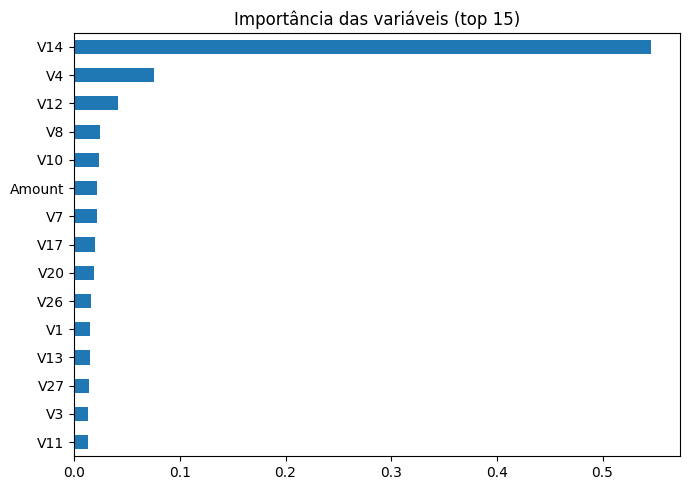

In [31]:
scaler = modelo_final.named_steps["scaler"]
clf = modelo_final.named_steps["clf"]

# Importância nativa do XGBoost
imp = pd.Series(clf.feature_importances_, index=X.columns).sort_values()
imp.tail(15).plot.barh(figsize=(7, 5), title="Importância das variáveis (top 15)")
plt.tight_layout(); plt.show()

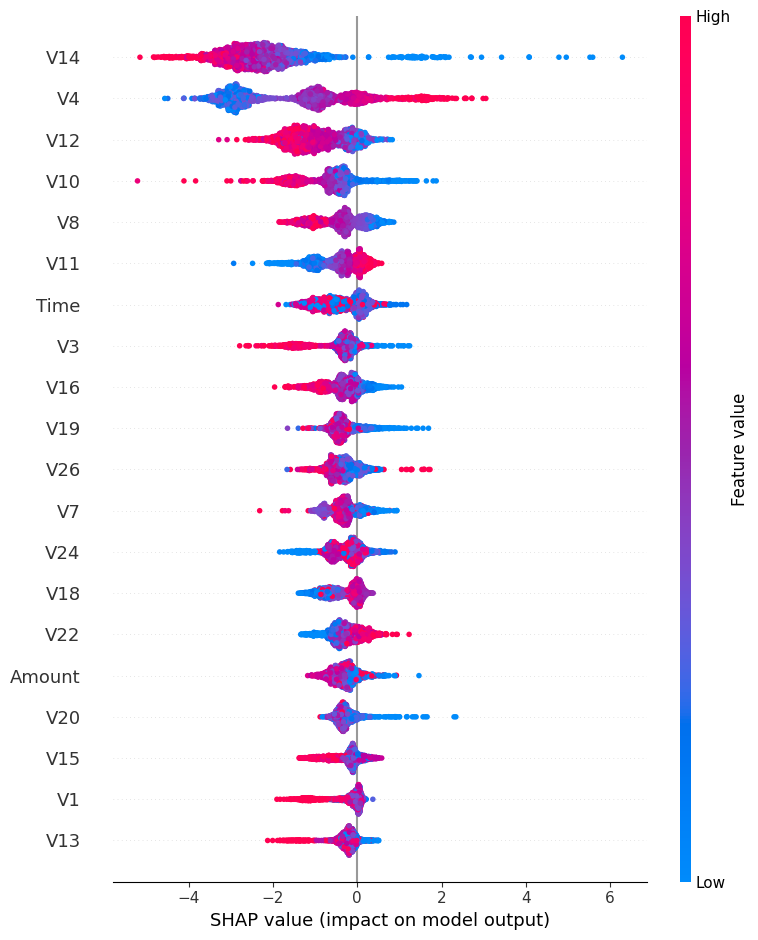

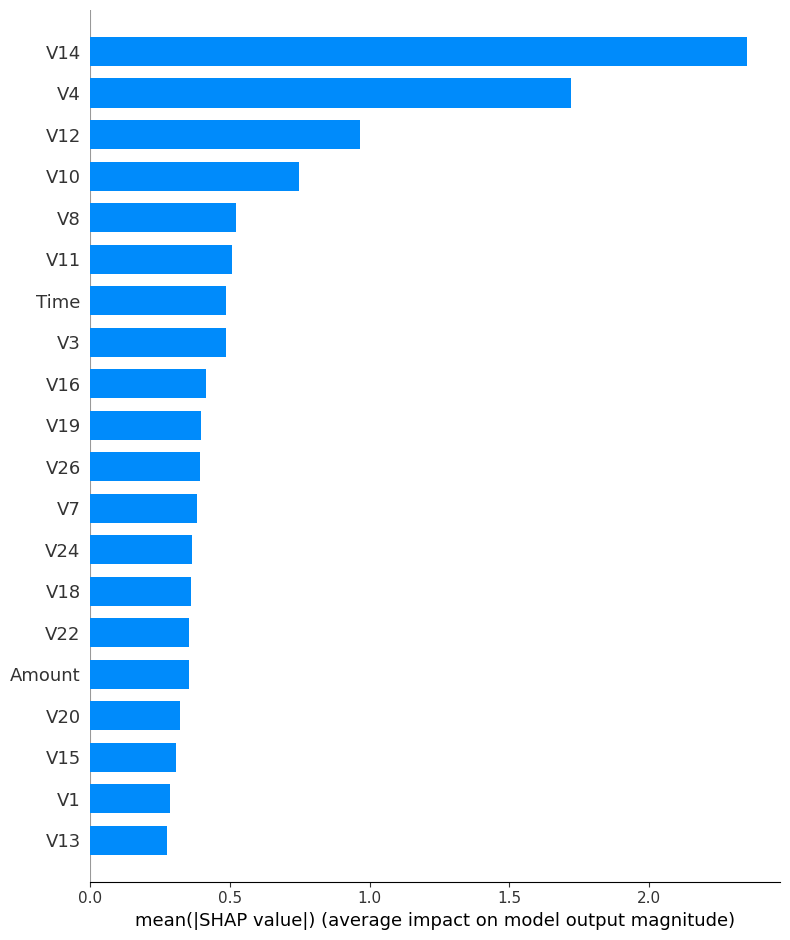

In [32]:
# SHAP numa amostra do teste (rápido) com os dados já padronizados, como o modelo os viu
amostra = X_test.sample(2000, random_state=RANDOM_STATE)
amostra_pad = pd.DataFrame(scaler.transform(amostra), columns=X.columns, index=amostra.index)

explainer = shap.TreeExplainer(clf)
shap_values = explainer.shap_values(amostra_pad)

shap.summary_plot(shap_values, amostra_pad)                    # direção e intensidade
shap.summary_plot(shap_values, amostra_pad, plot_type="bar")   # ranking médio

**Leitura do SHAP:** As variáveis que mais pesaram nas decisões do modelo foram V14, V4, V10 e V12, nessa ordem, tanto no ranking médio do SHAP quanto, com pequena diferença de posição, na importância nativa do XGBoost. No gráfico de pontos, valores baixos de V14 (e também de V10 e V12) empurram a previsão para fraude, enquanto valores altos de V4 empurram para fraude. Como V1 a V28 são componentes de PCA, a análise mostra quais componentes importam, mas não permite dar um significado de negócio a cada um. Além disso, o SHAP mostra associação, não causa. A amostra de 2.000 transações do teste tem poucas fraudes (a proporção real é de ~0,17%), então os padrões do gráfico são dominados por transações normais.

## Conclusões

- **Modelo escolhido e por quê:** XGBoost com `scale_pos_weight` (≈577) e hiperparâmetros escolhidos por busca (`max_depth=5`, `n_estimators=300`, `learning_rate=0.1`). Teve a maior PR-AUC entre os modelos comparados (0,88 no teste, antes do ajuste) e o melhor equilíbrio entre recall e precisão. A regressão logística com `class_weight="balanced"` teve o maior recall (0,9184), mas com precisão de apenas 0,0603.
- **Limiar escolhido e o trade-off recall × precisão:** 0,8, que deu o maior F1 (0,8617), com recall de 0,8265 (81 das 98 fraudes do teste) e precisão de 0,9000. Baixar o limiar para 0,1 sobe o recall para 0,8571, mas a precisão cai para 0,7778. O limiar foi escolhido no próprio conjunto de teste, que tem só 98 fraudes, então diferenças de 1 ou 2 fraudes entre limiares são ruído.
- **O que eu mudei em relação à Expert:** segui o roteiro com limiar de 0,3 e `GridSearchCV` pelo recall, e o resultado foi um modelo com recall de 0,9286, mas precisão de 0,0443 (1.964 falsos alarmes para 91 fraudes pegas). Troquei o critério da busca para `average_precision` e passei a escolher o limiar pelo maior F1 numa tabela de 0,1 a 0,9. Também comparei a regressão logística com e sem balanceamento e limitei o `max_depth` do Random Forest em 12 para o treino não ficar lento.
- **Próximos passos:** escolher o limiar num conjunto de validação separado, usar uma amostra do SHAP que inclua todas as fraudes do teste, testar undersampling/oversampling, ampliar a busca de hiperparâmetros e criar variáveis de comportamento ao longo do tempo.